<h1 style="color:red" align = center>INTRODUCTION TO MACHINE LEARNING</h1>
<h1 style="color:red" align = center> ChurnGuard GROUP PROJECT </h1>
<h2 style="color:red"align = center>Instructor: Dr. Khaled Mohamad</h2>

### TEAM ROLES:

<table style="text-align:left">
<tr>
    <th>Member</th>
    <th>Student ID</th>
    <th>Role</th>
</tr>
<tr>
    <td>Tairuly Nursat</td>
    <td>24B031110</td>
    <td>EDA Lead</td>
</tr>
<tr>
    <td>Gaukarbek Akmaral</td>
    <td>24B031725</td>
    <td>Modelling Lead</td>
</tr>
<tr>
    <td>Bayandiev Alibek</td>
    <td>24B031696</td>
    <td>Report & Presentation Lead</td>
</tr>
</table>

In [1]:
# Imports of dataset and needed libraries. 
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency

import warnings 
warnings.filterwarnings("ignore")

df = pd.read_csv("Customer_Churn.csv") 

<h2 style="color:blue">1. Dataset Overview.</h2>

We used the **Iranian Churn** dataset from the UCI Machine Learning Repository:
`https://archive.ics.uci.edu/dataset/563/iranian+churn+dat`.
<br>The dataset contains customer information from an Iranian telecommunications company. It has **3150 rows** and **14 columns**: 13 features and one target column(`Churn`).

**Problem type:** classification.

**Target variable:** `Churn` - whether a customer leaves the company (`Churn = 1`) or stays (`Churn = 0`).



In [2]:
display(df.shape)
display(df.head())

(3150, 14)

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


<h2 style="color:blue">1.1 Data Types Overview.</h2>

<h4 style="color:orange">Our data consists of numerical dtypes.</h4>

We can divide our dataset column dtypes into 3 types:
- **Binary**(True/False, but using Integers)**:**
  - *1/0:*
    - `Complains`(had/ didn't have)
    - `Churn`(left/ stayed)
  - *2/1:*
    - `Tariff Plan`(contractual/ pay as you go)
    - `Status`(active/ non-active)
- **Common Integer:**
  - *With Limits:*
      - `Charge  Amount`(min - 0, max - 10)
      - `Age Group`(min - 1, max - 5)
  - *Without Limits:*
      - `Age`
      - `Call  Failures`
      - `Subscription Length`
      - `Seconds of Use`
      - `Frequency of use`
      - `Frequency of SMS`
      - `Distinct Called Numbers`
- **Flaot:**
  - `Customer Value`(The calculated value of customer)

We can observe that `df.info()` and `df.describe()`confirm that our words about devision of numerical dtypes are **True**.
Also we can see that there is **no missing values**.


*Our main prediction is that customers who **have filed complaints** and **experienced more call failures** are **more likely to churn** than customers who have not complained and experienced fewer call failures.*
<h4 style="color:brown">Detailed anaylysis of Target variable(Churn) is provided in section 3.</h4>

In [37]:
display(df.info())
display(df.describe()) 
display(df.isnull().sum())

print("Complains unique values:", df["Complains"].unique())
print("Churn unique values:", df["Churn"].unique())
print("Tariff Plan unique values:", df["Tariff Plan"].unique())
print("Status unique values:", df["Status"].unique())
print("Charge  Amount unique values:", np.sort(df["Charge  Amount"].unique()))
print("Age Group unique values:", np.sort(df["Age Group"].unique()))



<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)
memory usa

None

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000
mean,7.627937,0.076508,32.541905,0.942857,4472.459683,69.460635,73.174921,23.509841,2.826032,1.077778,1.248254,30.998413,470.972916,0.157143
std,7.263886,0.265851,8.573482,1.521072,4197.908687,57.413308,112.237560,17.217337,0.892555,0.267864,0.432069,8.831095,517.015433,0.363993
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,30.000000,0.000000,1391.250000,27.000000,6.000000,10.000000,2.000000,1.000000,1.000000,25.000000,113.801250,0.000000
50%,6.000000,0.000000,35.000000,0.000000,2990.000000,54.000000,21.000000,21.000000,3.000000,1.000000,1.000000,30.000000,228.480000,0.000000
75%,12.000000,0.000000,38.000000,1.000000,6478.250000,95.000000,87.000000,34.000000,3.000000,1.000000,1.000000,30.000000,788.388750,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

Complains unique values: [0 1]
Churn unique values: [0 1]
Tariff Plan unique values: [1 2]
Status unique values: [1 2]
Charge  Amount unique values: [ 0  1  2  3  4  5  6  7  8  9 10]
Age Group unique values: [1 2 3 4 5]


<h3 style="color:blue">2.1 Missing-values and Duplicates check.</h3>

In [3]:
display(df.isnull().sum())
display(df.duplicated().sum())
df[df.duplicated()]

Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

np.int64(300)

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
518,0,0,37,0,0,0,0,0,2,1,2,25,0.00,1
628,0,0,35,0,0,0,0,0,2,1,2,25,0.00,1
718,0,0,37,0,0,0,0,0,2,1,2,25,0.00,1
728,0,0,36,0,0,0,0,0,3,1,2,30,0.00,1
901,0,0,38,0,0,0,0,0,2,1,2,25,0.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3145,21,0,19,2,6697,147,92,44,2,2,1,25,721.98,0
3146,17,0,17,1,9237,177,80,42,5,1,1,55,261.21,0
3147,13,0,18,4,3157,51,38,21,3,1,1,30,280.32,0
3148,7,0,11,2,4695,46,222,12,3,1,1,30,1077.64,0


<h3 style="color:blue">2.2 Data cleaning.</h3>

In [39]:
df_clean = df.copy()
df_clean.drop_duplicates(inplace=True)
display(df_clean.shape)

display(df["Churn"].value_counts())
display(df_clean["Churn"].value_counts())

(2850, 14)

Churn
0    2655
1     495
Name: count, dtype: int64

Churn
0    2404
1     446
Name: count, dtype: int64

<h3 style="color:blue">2.3 Overall Conclusion.</h3>

We checked the dataframe for:
- *Missing-values*: **0 missing-values**
<br>There is no missing-values, so there is no reason to delete any row here.
<h4 style="color:orange">No imputation strategy is required, there is no missing-values, so there is no rows to edit here.(Не доразвитая идея)</h4>

- *Duplicates*: **300 duplicates**
<br>We need to prevent **data leakage**, because of duplicates. We will solve this problem by deleting duplicates.
<br>After we cleaned our data, the data now has **2850 rows** instead of **3150**.
<table style="text-align:left">
<tr>
    <th>Before</th>
    <th>After</th>
</tr>
<tr>
    <td>2850 rows</td>
    <td>3150 rows</td>
</tr>
<tr>
    <td>100% of data</td>
    <td>90.4% of data</td>
</tr>
<tr>
    <td>Rate of Churn is 16%(отредачить)</td>
    <td>Rate of Churn is 16%</td>
</tr>
</table>



<h2 style="color:blue">3. Hypotesis test and Churn analysis.</h2>

*We hypothesize that customers who **have filed complaints** and **experienced more call failures** are **more likely to churn** than customers who have not complained and experienced fewer call failures.*

It is hard to **visualize** `Call Failure`, so created a new column `High  Failure`, which means the dataset now has **15 columns** instead of **14**.

In [36]:
df_clean["Churn"].value_counts()

Churn
0    2404
1     446
Name: count, dtype: int64

<h3 style="color:blue">3.1 Churn X Complains connection.</h3>

<Axes: xlabel='Complains', ylabel='Churn'>

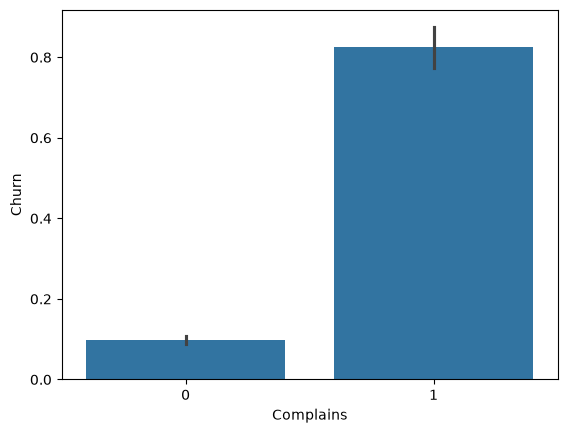

In [5]:
sns.barplot(data=df_clean, x='Complains', y='Churn')

<h3 style="color:blue">3.2 Churn X High Failure connection.</h3>

<Axes: xlabel='High  Failure', ylabel='Churn'>

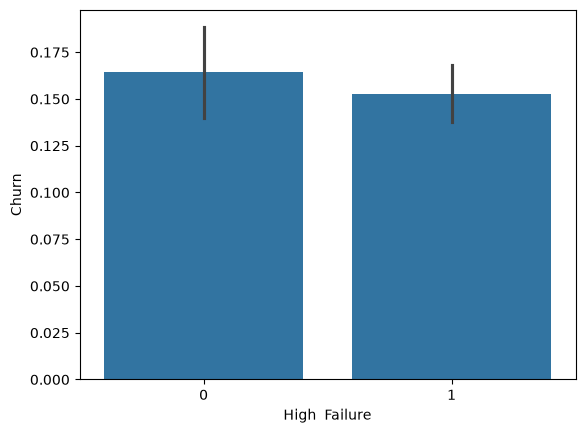

In [12]:
df_clean["High  Failure"] = (df_clean["Call  Failure"] > (df_clean["Call  Failure"].median()/2)).astype("int")
sns.barplot(data=df_clean, x='High  Failure', y='Churn')

<h3 style="color:blue">3.3 Barplots Analysis.</h3>


Our Barplots visualizations of `Complains` or `High  Failure` with `Churn` say that `Complains` has a huge influence on `Churn`, while `High  Failure` doesn't affect `Churn` too much. 

<h3 style="color:blue">3.4 Crosstable with both Complains and High Failure and its Analysis.</h3>

We created a crosstab with both `Complains` and `High Failure`, and we can clearly see that:
- Customers who *didn't experience many failures* and *didn't have any complaints* have only **12% of Churn**.
- Customers who *didn't experience many failures* but *had complaints* have **98% of Churn**.
- Customers who *experienced many failures* but *didn't have any complaints* have **9% of Churn**.
- Customers who *experienced many failures* and *had complaints* have **78% of Churn**.

In [10]:
crossCompAFail = pd.crosstab(df_clean["Churn"], [df_clean["High  Failure"],df_clean["Complains"]] , margins = True)
crossCompAFail

High  Failure    0         1        All
Complains        0   1     0    1      
Churn                                  
0              807   1  1557   39  2404
1              110  49   146  141   446
All            917  50  1703  180  2850

<h3 style="color:blue">3.5 Overall Conclusion.</h3>

Our hypothesis is only partly true:
- **True:** We can observe that customers who *had any complaints* have a **higher percentage of Churn**.
- **False:** We can observe that even if customers *experienced many failures*, they still have a **lower percentage of Churn**.
<h4 style="color:brown">More likely, customers who experienced many failures still use this telecom company because most of them were filtered out, so those who stay with this telecom company are the ones who didn't care about failures.</h4>